# Tahap 2 — Preprocessing Audio & Penetapan Dataset Eksperimen

Pipeline pengenalan pola suara (slide 10): **Akuisisi → _Preprocessing_ → Ekstraksi fitur → Klasifikasi → Evaluasi**.
Notebook ini menampilkan hasil tahap **preprocessing**. Seluruh logika ada di `src/preprocessing.py` dan
`src/data_utils.py`; proses massal dijalankan oleh `scripts/02_preprocess.py`.

| Langkah | Fungsi | Konsep materi |
|---|---|---|
| a. Konversi & *resampling* | `convert_to_wav()` | analog → digital; **sampling** 16 kHz (Nyquist 8 kHz); **quantization** PCM 16-bit = 65.536 level |
| b. *Trimming* hening | `trim_silence()` | energi/amplitudo di domain waktu |
| c. Segmentasi batuk | `segment_coughs()` | envelope energi RMS + *hysteresis threshold*; batuk = suara **nonperiodik** |
| d. Reduksi noise | `reduce_noise()` | STFT / Fourier → *spectral gating* di domain frekuensi |
| e. Normalisasi | `normalize()` | amplitudo puncak → rentang −1..1; pad/potong ke durasi tetap untuk CNN |

In [1]:
import sys, json, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings('ignore')

import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from src.config import load_config, set_seed
from src import data_utils as du, preprocessing as pp
from src.plots import setup_style, save_fig, save_table, plot_preprocessing_steps, plot_spectrogram_compare

cfg = load_config(); set_seed(cfg.seed); setup_style()
P = cfg.preprocessing
print('Parameter preprocessing:'); print(json.dumps(P, indent=1))

Parameter preprocessing:
{
 "n_jobs": -2,
 "bit_depth": 16,
 "min_duration_s": 0.3,
 "trim": {
  "top_db": 30,
  "frame_length": 512,
  "hop_length": 128
 },
 "segmentation": {
  "frame_ms": 25,
  "hop_ms": 10,
  "th_high_mult": 2.0,
  "th_low_mult": 0.5,
  "tolerance_ms": 30,
  "padding_s": 0.2,
  "min_cough_s": 0.2
 },
 "noise_reduction": {
  "enabled": true,
  "stationary": true,
  "prop_decrease": 0.8
 },
 "normalization": {
  "method": "peak",
  "peak_target": 0.99,
  "rms_target_db": -20
 },
 "pad_on_save": false
}


## 1. Populasi & split final

Split **stratified 70/15/15 per `uuid`** (seed 42) dilakukan pada populasi asli, **sebelum** undersampling.
Undersampling kelas *healthy* (rasio `healthy_to_covid_ratio`) hanya diterapkan pada **train** (kolom `dipakai`);
val/test mempertahankan distribusi alami agar evaluasi jujur.

In [2]:
PROC = cfg.paths.processed
splits = {e: pd.read_csv(PROC / f'splits_{e}.csv') for e in ['A', 'B']}
man = {e: pd.read_csv(PROC / f'manifest_{e}.csv') for e in ['A', 'B']}
for e in ['A', 'B']:
    sp = splits[e]
    t_all = pd.crosstab(sp['split'], sp['label_name'], margins=True, margins_name='total')
    t_man = pd.crosstab(man[e]['split'], man[e]['label_name'], margins=True, margins_name='total')
    t_all = t_all.reindex(['train', 'val', 'test', 'total']); t_man = t_man.reindex(['train', 'val', 'test', 'total'])
    tab = pd.concat({'split (populasi penuh)': t_all, 'manifest (dipakai, lolos preprocessing)': t_man}, axis=1)
    save_table(tab, f'02_jumlah_per_split_{e}')
    print(f'=== Eksperimen {e} ==='); display(tab)

=== Eksperimen A ===


split (populasi penuh)                 \
label_name               COVID-19 healthy  total   
split                                              
train                         504    7092   7596   
val                           108    1520   1628   
test                          108    1520   1628   
total                         720   10132  10852   

           manifest (dipakai, lolos preprocessing)                
label_name                                COVID-19 healthy total  
split                                                             
train                                          502    1507  2009  
val                                            108    1514  1622  
test                                           108    1516  1624  
total                                          718    4537  5255

=== Eksperimen B ===


split (populasi penuh)                \
label_name               COVID-19 healthy total   
split                                             
train                         329     380   709   
val                            71      81   152   
test                           70      82   152   
total                         470     543  1013   

           manifest (dipakai, lolos preprocessing)                
label_name                                COVID-19 healthy total  
split                                                             
train                                          329     378   707  
val                                             71      81   152  
test                                            70      82   152  
total                                          470     541  1011

In [3]:
stB = json.loads((cfg.paths.logs / 'label_stats_B.json').read_text(encoding='utf-8'))
pd.Series(stB, name='Eksperimen B — majority vote label ahli').to_frame()

,Eksperimen B — majority vote label ahli
experiment,B
berlabel_ahli,2841
multi_ahli,130
konflik_antar_ahli,124
konflik_covid_vs_healthy,34
dibuang_seri,36
konflik_diselesaikan_vote,88
vote_covid_atau_healthy,1223
dibuang_cough_detected,210
n_covid,470


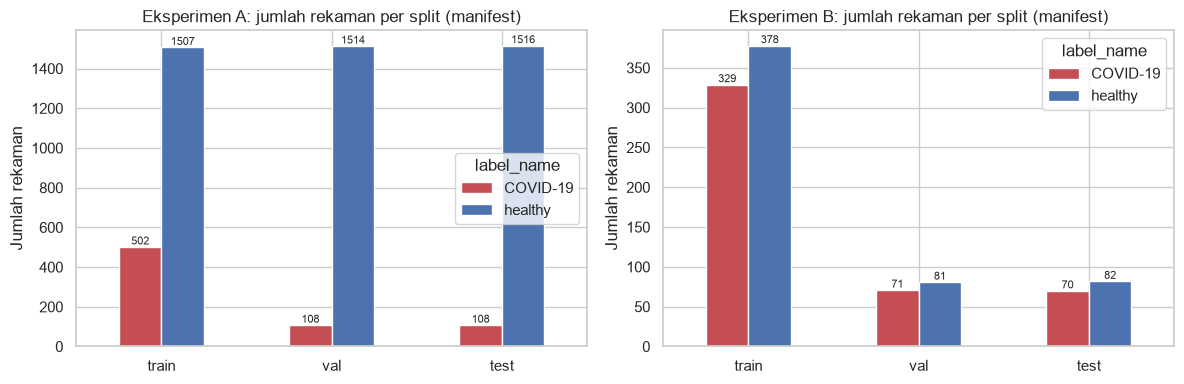

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, e in zip(axes, ['A', 'B']):
    t = pd.crosstab(man[e]['split'], man[e]['label_name']).reindex(['train', 'val', 'test'])
    t.plot.bar(ax=ax, color=['#C44E52', '#4C72B0'], rot=0)
    for c in ax.containers: ax.bar_label(c, fontsize=8)
    ax.set_title(f'Eksperimen {e}: jumlah rekaman per split (manifest)'); ax.set_xlabel(''); ax.set_ylabel('Jumlah rekaman')
fig.tight_layout(); save_fig(fig, '02_jumlah_per_split'); plt.show()

## 2. Before/after tiap langkah — 1 contoh COVID-19 dan 1 contoh *healthy*

Contoh dipilih acak (seed 42) dari train Eksperimen A dengan `cough_detected ≥ 0.95` dan ≥ 2 segmen batuk
agar segmentasi terlihat jelas. `preprocess_file(..., return_signals=True)` menjalankan ulang langkah a–e
dan mengembalikan sinyal antara.

In [5]:
src_map = du.load_metadata().set_index('uuid')['audio_path']
cand = man['A'][(man['A']['split'] == 'train') & (man['A']['cough_detected'] >= 0.95) & (man['A']['n_segmen'] >= 2)]
ex = {}
for lab, name in [(1, 'COVID-19'), (0, 'healthy')]:
    u = cand[cand['label'] == lab].sample(1, random_state=cfg.seed)['uuid'].iloc[0]
    ex[name] = pp.preprocess_file(u, src_map[u], cfg, return_signals=True)
    r = ex[name]; print(f"{name:9s} uuid={u}  asli={r['durasi_asli_s']} s  trim={r['durasi_trim_s']} s  segmen={r['segments']}")

COVID-19  uuid=2617553e-8579-457f-97c7-fa0446bf1d2d  asli=8.4 s  trim=4.272 s  segmen=[(0.0, 1.13), (2.38, 3.69), (3.74, 4.272)]
healthy   uuid=e3467c7b-fbbc-4a90-95fb-ed401a4758d2  asli=9.9 s  trim=6.904 s  segmen=[(0.76, 1.48), (4.59, 5.27)]


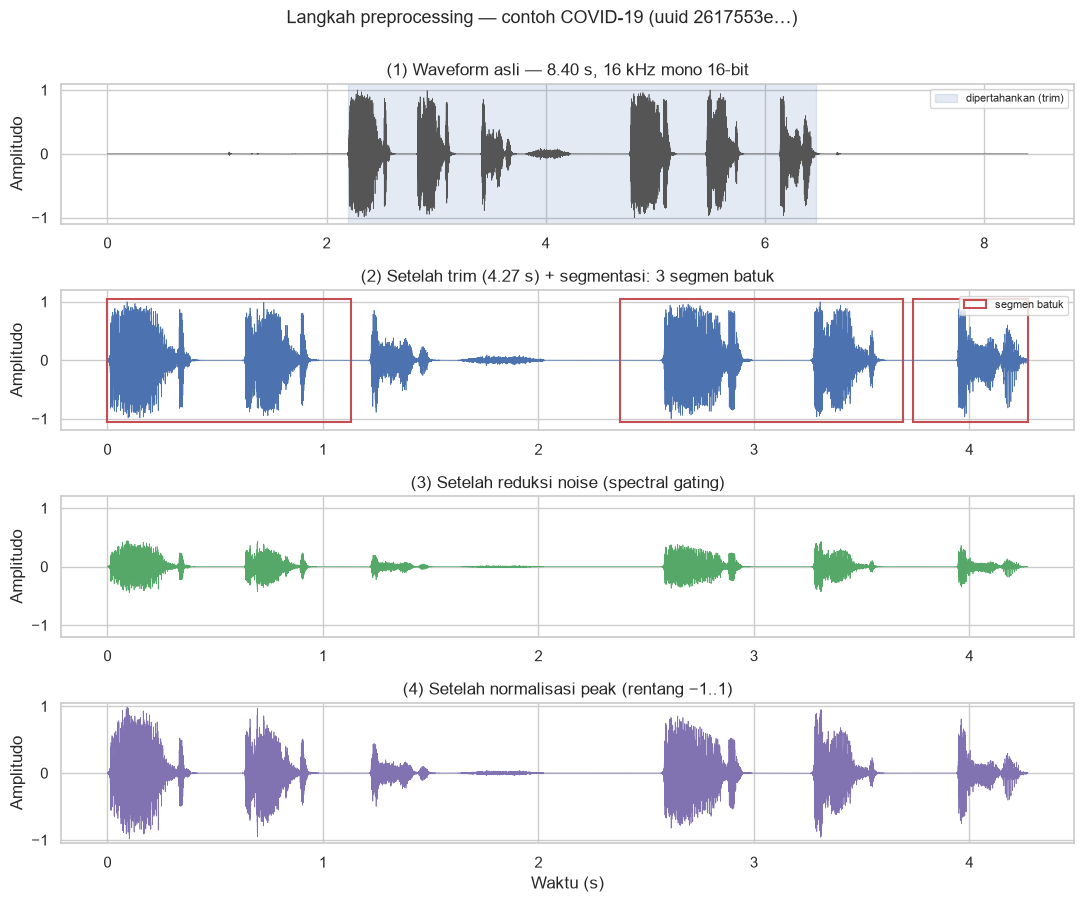

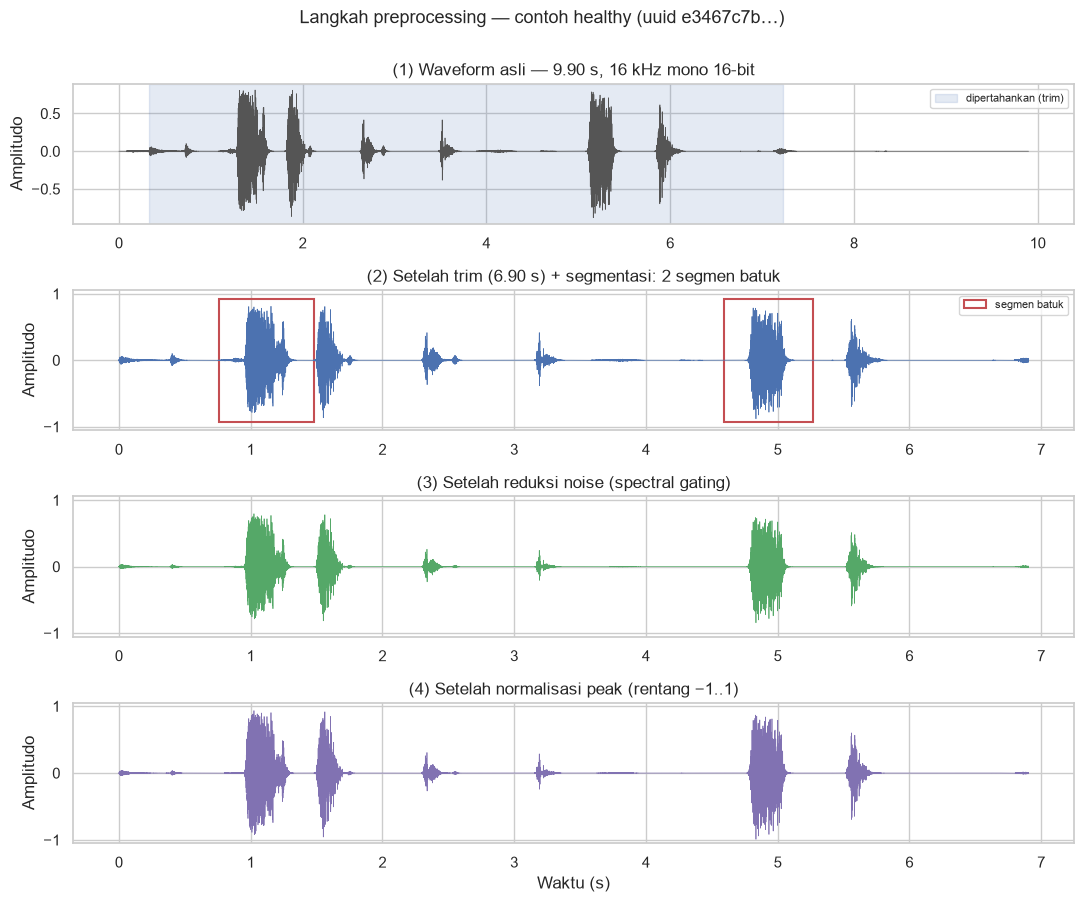

In [6]:
for name, fn in [('COVID-19', '02_langkah_preprocessing_covid'), ('healthy', '02_langkah_preprocessing_healthy')]:
    fig = plot_preprocessing_steps(ex[name], title=f'Langkah preprocessing — contoh {name} (uuid {ex[name]["uuid"][:8]}…)')
    save_fig(fig, fn); plt.show()

Spektrogram (domain **frekuensi**–waktu, hasil STFT) memperlihatkan efek *spectral gating*: energi latar yang
merata di semua frekuensi (noise stasioner) dilemahkan, sementara ledakan energi lebar-pita khas batuk
(nonperiodik, tanpa harmonik jelas) dipertahankan.

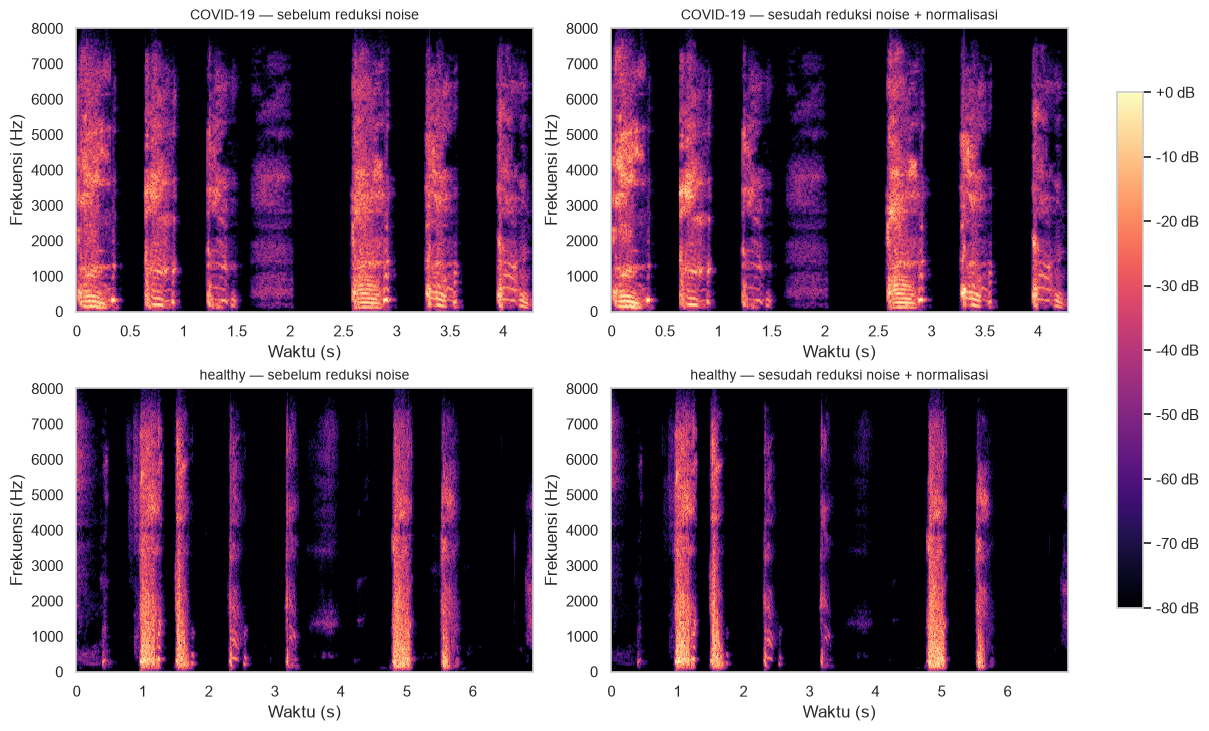

In [7]:
fig = plot_spectrogram_compare(ex, sr=cfg.audio.sample_rate)
save_fig(fig, '02_spektrogram_sebelum_sesudah_noise'); plt.show()

## 3. Distribusi durasi sebelum/sesudah preprocessing per kelas

In [8]:
d = pd.concat([man[e].assign(eksperimen=e) for e in ['A', 'B']], ignore_index=True)
long = d.melt(id_vars=['eksperimen', 'label_name'], value_vars=['durasi_asli_s', 'durasi_trim_s', 'durasi_batuk_s'],
              var_name='tahap', value_name='durasi_s')
long['tahap'] = long['tahap'].map({'durasi_asli_s': 'asli', 'durasi_trim_s': 'setelah trim', 'durasi_batuk_s': 'total segmen batuk'})
ring = long.groupby(['eksperimen', 'label_name', 'tahap'])['durasi_s'].describe()[['count', 'mean', '50%', 'std', 'min', 'max']].round(2)
save_table(ring, '02_ringkasan_durasi'); ring

count  mean   50%   std   min  \
eksperimen label_name tahap                                                
A          COVID-19   asli                 718.0  8.34  9.78  2.32  1.08   
                      setelah trim         718.0  4.60  4.40  2.45  0.30   
                      total segmen batuk   718.0  1.57  1.43  1.05  0.00   
           healthy    asli                4537.0  8.21  9.72  2.31  1.14   
                      setelah trim        4537.0  4.22  3.98  2.44  0.30   
                      total segmen batuk  4537.0  1.47  1.30  1.06  0.00   
B          COVID-19   asli                 470.0  8.59  9.78  2.08  2.34   
                      setelah trim         470.0  4.84  4.92  2.29  0.41   
                      total segmen batuk   470.0  1.86  1.75  1.13  0.00   
           healthy    asli                 541.0  7.83  9.60  2.52  1.08   
                      setelah trim         541.0  3.61  3.17  2.44  0.30   
                      total segmen batuk   541.0  1.11  0.99  0.85  0.00   

                                            max  
eksperimen label_name tahap                      
A          COVID-19   asli                13.08  
                      setelah trim        10.02  
                      total segmen batuk   4.76  
           healthy    asli                15.24  
                      setelah trim        13.71  
                      total segmen batuk   6.35  
B          COVID-19   asli                13.68  
                      setelah trim         9.88  
                      total segmen batuk   6.37  
           healthy    asli                10.02  
                      setelah trim         9.94  
                      total segmen batuk   4.64

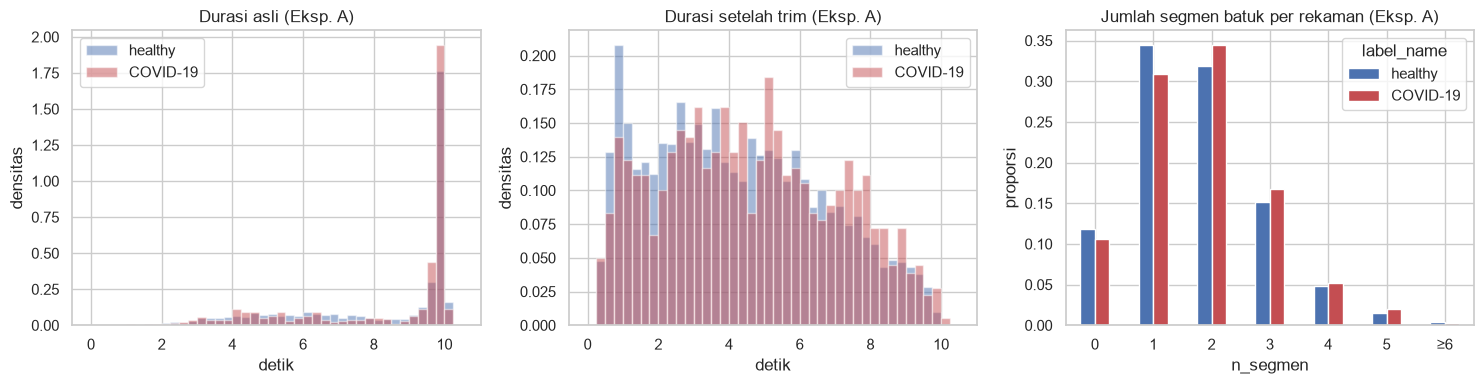

In [9]:
A = man['A']
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
bins = np.linspace(0, 10.5, 43)
for ax, col, ttl in [(axes[0], 'durasi_asli_s', 'Durasi asli'), (axes[1], 'durasi_trim_s', 'Durasi setelah trim')]:
    for lab, c in [('healthy', '#4C72B0'), ('COVID-19', '#C44E52')]:
        ax.hist(A.loc[A['label_name'] == lab, col], bins=bins, density=True, alpha=0.5, color=c, label=lab)
    ax.set_title(f'{ttl} (Eksp. A)'); ax.set_xlabel('detik'); ax.set_ylabel('densitas'); ax.legend()
ax = axes[2]
cnt = pd.crosstab(A['n_segmen'].astype(int).clip(upper=6), A['label_name'], normalize='columns')
cnt.index = [str(int(i)) if i < 6 else '≥6' for i in cnt.index]
cnt[['healthy', 'COVID-19']].plot.bar(ax=ax, color=['#4C72B0', '#C44E52'], rot=0)
ax.set_title('Jumlah segmen batuk per rekaman (Eksp. A)'); ax.set_xlabel('n_segmen'); ax.set_ylabel('proporsi')
fig.tight_layout(); save_fig(fig, '02_distribusi_durasi'); plt.show()

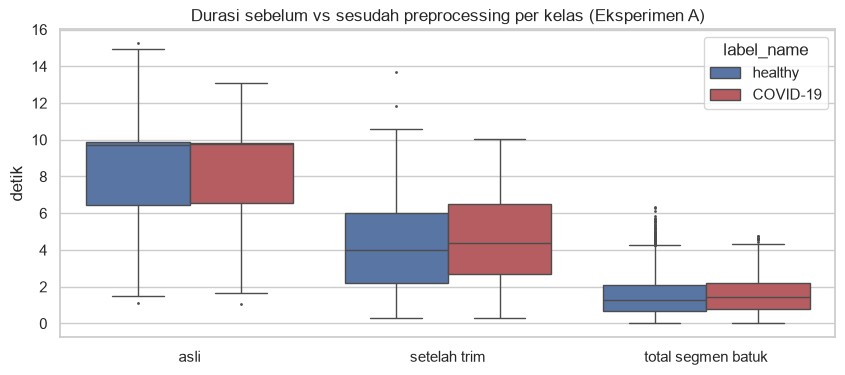

In [10]:
fig, ax = plt.subplots(figsize=(10, 4))
sns.boxplot(data=long[long['eksperimen'] == 'A'], x='tahap', y='durasi_s', hue='label_name',
            palette={'healthy': '#4C72B0', 'COVID-19': '#C44E52'}, ax=ax, fliersize=1)
ax.set_title('Durasi sebelum vs sesudah preprocessing per kelas (Eksperimen A)'); ax.set_xlabel(''); ax.set_ylabel('detik')
save_fig(fig, '02_boxplot_durasi'); plt.show()

## 4. File gagal / dibuang

In [11]:
err = pd.read_csv(cfg.paths.logs / 'preprocess_errors.csv')
summ = json.loads((cfg.paths.logs / 'preprocess_summary.json').read_text(encoding='utf-8'))
print('Jumlah file gagal/dibuang:', len(err))
print('Rekaman tanpa segmen terdeteksi (n_segmen=0) di manifest A:', int((A['n_segmen'] == 0).sum()))
display(err['error'].str.replace(r'\(.*', '', regex=True).value_counts().to_frame('jumlah') if len(err) else pd.DataFrame())

Jumlah file gagal/dibuang: 17
Rekaman tanpa segmen terdeteksi (n_segmen=0) di manifest A: 611


,jumlah
error,
terlalu pendek setelah trim,17


## 5. Catatan

- Wav di `data/processed/wav/` **tidak** di-*pad*; panjang tetap (`max_duration_s` = 10 s) diterapkan saat
  memuat input CNN (`normalize(..., target_duration_s=10)`), agar fitur statistik ML klasik (mis. rata-rata ZCR/energi)
  tidak terdistorsi oleh nol-padding.
- Rekaman dengan `n_segmen = 0` dipertahankan (sudah lolos `cough_detected ≥ 0.8`); segmentasi berbasis energi
  bisa gagal pada rekaman yang energinya merata (batuk beruntun/noise tinggi).
- Reduksi noise & normalisasi bekerja per rekaman secara independen → tidak ada *data leakage* antar split.